# CSE 4095 — Class 4: Comparing Models Fairly
Use AI to help design and implement the workflow, but you must control the comparison.

## 1. Choose your track
Choose classification (`high_exam_score`) or regression (`exam_score`). Write your prediction scenario.

In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv("class1_student_habits.csv")

# Create the classification target
df["high_exam_score"] = df["exam_score"].apply(
    lambda score: "Yes" if score >= 80 else "No"
)

# Show the first few rows
df[["exam_score", "high_exam_score"]].head()

,exam_score,high_exam_score
0,64.6,No
1,81.5,Yes
2,92.0,Yes
3,100.0,Yes
4,68.5,No


In [8]:
# Count the number of students in each class
class_counts = df["high_exam_score"].value_counts()

class_counts


high_exam_score
No     151
Yes     99
Name: count, dtype: int64

In [7]:

# Calculate the percentage of students in each class
class_percentages = df["high_exam_score"].value_counts(normalize=True) * 100

class_percentages

high_exam_score
No     60.4
Yes    39.6
Name: proportion, dtype: float64

Part 1 Questions:

1. What are you trying to predict?  
- I am trying to predict whether a student will have a high exam score. A high exam score is defined as an exam score of 80 or higher.

2. Why is this a classification problem?
- This is a classification problem because the model is predicting one of two categories, either "Yes" for a high exam score or "No" for a score below 80.

3. What percentage of students belong to each class?  
- 60.4% of the students are in the "No" class, while 39.6% are in the "Yes" class.

4. Is the dataset approximately balanced?  
- The dataset is not perfectly balanced because there are more students in the "No" class than the "Yes" class. However, the difference is not extremely large, so the classes are still reasonably balanced.

## 2. Define X and y
Use legitimate features. Explain excluded columns.

In [9]:
# TODO: define X, y, and feature columns
# Select the required features
features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes"
]

# Define X and y
X = df[features]
y = df["high_exam_score"]

# Identify numerical and categorical columns
numerical_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes"
]

categorical_features = [
    "prior_programming_experience",
    "study_group"
]

# Check the selected data
X.head()

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes
0,1.3,7.7,71.8,8,Strong,No,0
1,9.4,6.6,74.2,14,NaN,Yes,52
2,11.2,6.1,70.3,15,Some,No,7
3,10.8,7.6,77.1,16,Strong,No,12
4,8.0,5.6,89.7,15,NaN,Yes,12


Part 2 Question:
1. Why would using exam_score be target leakage?  
- Using exam_score would be target leakage because high_exam_score is created directly from exam_score. Since the model is supposed to predict whether the exam score is 80 or higher, giving it the actual exam_score would reveal the answer and make the model's performance unrealistically high.

## 3. Train/test split
Create an 80/20 split. Keep the test set for final evaluation.

In [10]:
# TODO: train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Part 3 Questions:
1. Why are we holding the test set aside?  
- We are holding the test set aside so we can evaluate the final model on data that was not used during model selection or tuning. This gives us a more unbiased estimate of how the model may perform on new data.
2. What could happen if we repeatedly check test accuracy while modifying our model?  
- If we repeatedly check test accuracy while changing the model, we may start making decisions based on the test set. This can cause the model to indirectly overfit to the test data, making the final test accuracy less reliable as an independent evaluation.

## 4. Preprocessing pipeline
Create a majority-class baseline for classification or mean baseline for regression.

In [11]:
# TODO: baseline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Preprocessing for numerical columns
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both types of preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Part 4 Questions:
1. Why should preprocessing be included inside the pipeline?  
- Preprocessing should be included inside the pipeline so the same steps are applied consistently whenever the model is trained or evaluated. This also helps prevent information from leaking between different parts of the data.
2. Why is this especially important when using cross-validation?  
- It is especially important during cross-validation because the preprocessing should be fitted only on the training folds, then applied to the validation fold. Keeping preprocessing inside the pipeline makes sure this happens correctly for every fold.
3. Which of the models in this assignment are sensitive to feature scaling?  
- Logistic Regression is sensitive to feature scaling because it uses numerical optimization and can be affected when features are on very different scales.
4. Do Decision Trees and Random Forests generally require scaling?  
- No. Decision Trees and Random Forests generally do not require scaling because they make decisions using feature thresholds and splits rather than depending on the numerical scale of the features.

## 5. Baseline
Handle missing values and categorical variables.

In [12]:
# TODO: preprocessing setup
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

# Create the majority-class baseline pipeline
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

# Evaluate using 5-fold cross-validation on the training data only
baseline_scores = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy scores:", baseline_scores)
print("Mean CV accuracy:", baseline_scores.mean())
print("Standard deviation:", baseline_scores.std())

CV accuracy scores: [0.625 0.6   0.6   0.6   0.6  ]
Mean CV accuracy: 0.6050000000000001
Standard deviation: 0.010000000000000009


Part 5 Questions:

1. What does the baseline do?
- The baseline always predicts the most common class in the training data. It gives us a simple reference point to compare the machine-learning models against.

2. What is its mean CV accuracy?
- The mean cross-validation accuracy of the baseline is 0.605, or 60.5%.

3. Why should our machine-learning models be compared with this baseline?
- The machine-learning models should be compared with the baseline to see whether they actually perform better than simply predicting the most common class every time. If a model cannot outperform the baseline, then it may not be learning useful patterns from the data.

Part 6 Questions:

1. What happens during 5-fold cross-validation?
- The training data is split into five parts, called folds. The model trains on four folds and is validated on the remaining fold. This process repeats five times so that each fold is used once as the validation set.

2. How many times is each model trained?
- Each model is trained five times, once for each fold used as the validation set.

3. Why is cross-validation more informative than evaluating a model using only one training/validation split?
- Cross-validation is more informative because it evaluates the model across several different splits of the training data instead of relying on just one split. This gives a better idea of how consistently the model performs.

4. Why do we still keep a separate final test set?
- We keep a separate final test set so we can evaluate the selected model on completely unseen data after model comparison and tuning are finished. This gives us a more independent estimate of how well the model may generalize.

## 6. Cross-validation comparison
Compare a small set of models using the same folds and metrics.

In [13]:
# TODO: cross-validation model comparison
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression())
])

# Decision Tree pipeline
tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

# Random Forest pipeline
forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [14]:
#Part 8 — Compare the Models with Cross-Validation

import pandas as pd

from sklearn.model_selection import cross_validate
from sklearn.metrics import precision_score, recall_score, make_scorer

# Define the metrics
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Yes",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Yes",
        zero_division=0
    )
}

# Models to compare
models = {
    "Majority Baseline": baseline_pipeline,
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": tree_pipeline,
    "Random Forest": forest_pipeline
}

# Store the results
results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std. Accuracy": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

# Create comparison table
comparison_table = pd.DataFrame(results)

comparison_table

,Model,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,Majority Baseline,0.605,0.010000,0.000000,0.000000
1,Logistic Regression,0.735,0.037417,0.693968,0.621667
2,Decision Tree,0.645,0.064031,0.566667,0.467500
3,Random Forest,0.660,0.051478,0.600000,0.468333


Part 8 Questions:

1. Which model has the highest mean CV accuracy?
- Logistic Regression has the highest mean cross-validation accuracy at 0.735, or 73.5%.

2. How large are the differences?
- Logistic Regression has a mean CV accuracy about 7.5 percentage points higher than Random Forest, 9 percentage points higher than Decision Tree, and 13 percentage points higher than the majority baseline. These differences should still be interpreted together with the variation across folds.

3. Which model has the highest recall?
- Logistic Regression has the highest recall at about 0.622, or 62.2%.

4. Do all metrics identify the same model?
- Yes. Logistic Regression has the highest mean CV accuracy, precision, and recall among the machine-learning models. This suggests that it performed best overall in this comparison, although the results should still be interpreted cautiously rather than concluding that it is definitely superior.

5. How much does performance vary between folds?
- Logistic Regression has a standard deviation of about 0.037, Decision Tree about 0.064, and Random Forest about 0.051. This means Logistic Regression varies the least among the three machine-learning models, while Decision Tree varies the most. The majority baseline has very little variation, with a standard deviation of 0.010.

Part 9 Question:

1. What is the difference between a model parameter and a hyperparameter?
- A model parameter is something the model learns automatically from the training data during training. A hyperparameter is a setting that is chosen before training and controls how the model is built or trained.

Using `max_depth` as an example:
- `max_depth` is a hyperparameter because we choose its value before training the Decision Tree. It controls how deep the tree is allowed to grow. The actual split rules and thresholds inside the tree are model parameters because the model learns them from the training data.

## 7. Tune one hyperparameter
Tune decision-tree max_depth using cross-validation on the training data.

In [15]:
# TODO: tune max_depth
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import pandas as pd

# Depth values required by the assignment
depths = [1, 2, 3, 4, 6, 8, None]

depth_results = []

for depth in depths:

    tree_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_validate(
        tree_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        return_train_score=True
    )

    depth_results.append({
        "max_depth": depth,
        "Training Accuracy": scores["train_score"].mean(),
        "CV Accuracy": scores["test_score"].mean(),
        "CV Std.": scores["test_score"].std()
    })

# Create the results table
depth_table = pd.DataFrame(depth_results)

depth_table

,max_depth,Training Accuracy,CV Accuracy,CV Std.
0,1.0,0.65250,0.615,0.043589
1,2.0,0.72500,0.610,0.064420
2,3.0,0.76375,0.600,0.052440
3,4.0,0.81375,0.645,0.064031
4,6.0,0.89625,0.645,0.078102
5,8.0,0.96250,0.640,0.033912
6,NaN,1.00000,0.630,0.048477


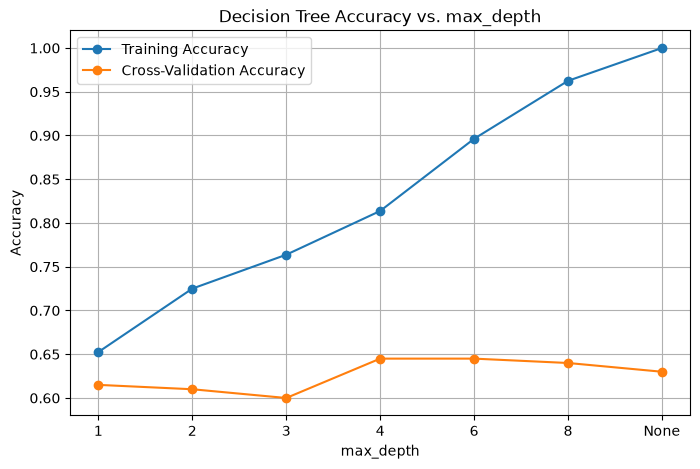

In [16]:
#   Part 11 — Visualize Model Complexity

import matplotlib.pyplot as plt

# Labels for the x-axis
depth_labels = ["1", "2", "3", "4", "6", "8", "None"]

plt.figure(figsize=(8, 5))

plt.plot(
    depth_labels,
    depth_table["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_labels,
    depth_table["CV Accuracy"],
    marker="o",
    label="Cross-Validation Accuracy"
)

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Accuracy vs. max_depth")
plt.legend()
plt.grid(True)

plt.show()

Part 11 Questions:

1. What happens to training accuracy as max_depth increases?
- Training accuracy increases as max_depth increases. It rises from about 65.3% at depth 1 to 100% when there is no depth limit.

2. What happens to cross-validation accuracy?
- Cross-validation accuracy does not keep increasing with depth. It starts around 61.5%, decreases slightly at depths 2 and 3, then improves to about 64.5% at depths 4 and 6. After that, it begins to decrease again.

3. At what depth does the tree appear to perform best on unseen data?
- The tree appears to perform best at max_depth 4 or 6 because both have the highest mean cross-validation accuracy of 64.5%. Since their performance is the same, the simpler depth 4 tree may be preferred.

4. Do you see evidence of underfitting?
- Yes. The shallow trees, especially max_depth 1, show signs of underfitting because both the training accuracy and cross-validation accuracy are relatively low.

5. Do you see evidence of overfitting?
- Yes. At larger depths, training accuracy continues to increase while cross-validation accuracy stops improving and begins to decrease. This is especially clear at max_depth 8 and None, where training accuracy is very high but cross-validation accuracy is lower.

Part 12 Questions:

1. Which Decision Tree depth appears to underfit?
- Max_depth 1 appears to underfit because both its training accuracy and cross-validation accuracy are relatively low. This suggests the tree is too simple to capture enough of the patterns in the data.

2. Which depth appears to generalize best?
- Max_depth 4 appears to generalize best. It has the highest mean cross-validation accuracy of 64.5%, tied with max_depth 6, but depth 4 is simpler and has slightly lower variation across folds.

3. Do the deepest trees show signs of overfitting?
- Yes. The deeper trees show signs of overfitting because their training accuracy becomes very high while their cross-validation accuracy stops improving and begins to decrease.

4. Why should we not simply choose the tree with the highest training accuracy?
- We should not choose a tree based only on training accuracy because a model can fit the training data extremely well but perform worse on unseen data. Cross-validation accuracy gives a better indication of how well the model generalizes.

In [17]:
#Part 14 — Compare the Tuned Tree Again

selected_depth = 4 

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import pandas as pd

# Create the tuned Decision Tree
tuned_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=selected_depth,
        random_state=42
    ))
])

# Models to compare
models_part14 = {
    "Majority Baseline": baseline_pipeline,
    "Logistic Regression": logistic_pipeline,
    "Original Decision Tree": tree_pipeline,
    "Tuned Decision Tree": tuned_tree_pipeline,
    "Random Forest": forest_pipeline
}

# Store results
results_part14 = []

for model_name, model in models_part14.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    results_part14.append({
        "Model": model_name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std. Accuracy": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

# Updated comparison table
comparison_table_part14 = pd.DataFrame(results_part14)

comparison_table_part14.round(3)

,Model,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,Majority Baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.735,0.037,0.694,0.622
2,Original Decision Tree,0.645,0.064,0.567,0.467
3,Tuned Decision Tree,0.645,0.064,0.567,0.467
4,Random Forest,0.660,0.051,0.600,0.468


Note:
- The original and tuned Decision Trees have identical results because the original tree already used max_depth 4, and the cross-validation experiment also selected max_depth 4 as the preferred depth.

Part 13 — Select a Decision-Tree Depth

- I selected max_depth 4 for the Decision Tree. Both max_depth 4 and 6 had the highest mean cross-validation accuracy of 64.5%, but depth 4 had lower variation across folds, with a standard deviation of about 0.064 compared with about 0.078 for depth 6. Depth 4 is also the simpler model. Since increasing the depth beyond 4 did not improve mean cross-validation accuracy while training accuracy continued to increase, max_depth 4 provides a reasonable balance between performance, variability, and model complexity.

Part 14 Question:

1. Based only on the training-data cross-validation results, which model would you carry forward to final evaluation?
- I would carry Logistic Regression forward to the final evaluation. It has the highest mean cross-validation accuracy at 73.5%, compared with 66.0% for Random Forest and 64.5% for both Decision Trees. It also has the highest precision and recall, and its accuracy varies less across folds than the Decision Tree and Random Forest. Based on these cross-validation results, Logistic Regression appears to be the strongest model to evaluate on the final test set.

## 8. Final test evaluation
Choose one workflow, fit on full training data, and evaluate once on the test set.

In [18]:
# TODO: final test evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.dummy import DummyClassifier

# Fit the selected Logistic Regression pipeline
logistic_pipeline.fit(X_train, y_train)

# Make predictions on the held-out test set
y_test_pred = logistic_pipeline.predict(X_test)

# Calculate test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(
    y_test,
    y_test_pred,
    pos_label="Yes",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    pos_label="Yes",
    zero_division=0
)

test_confusion_matrix = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["No", "Yes"]
)

# Majority-class baseline on the test set
majority_test_model = DummyClassifier(strategy="most_frequent")
majority_test_model.fit(X_train, y_train)

majority_test_pred = majority_test_model.predict(X_test)

majority_test_accuracy = accuracy_score(
    y_test,
    majority_test_pred
)

# Display results
print("Final Logistic Regression Test Results")
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)

print("\nConfusion Matrix:")
print(test_confusion_matrix)

print("\nMajority-Class Test Accuracy:")
print(majority_test_accuracy)

Final Logistic Regression Test Results
Accuracy: 0.84
Precision: 0.8333333333333334
Recall: 0.75

Confusion Matrix:
[[27  3]
 [ 5 15]]

Majority-Class Test Accuracy:
0.6


Part 15 Questions:

1. How does final test accuracy compare with mean CV accuracy?
- The final test accuracy is 84%, while the mean cross-validation accuracy was 73.5%. The test accuracy is about 10.5 percentage points higher than the mean CV accuracy.

2. Is it reasonably consistent with what you observed during cross-validation?

- The final test accuracy of 84% is higher than the mean cross-validation accuracy of 73.5%. The difference is noticeable, but performance can vary depending on the particular observations in the test set, so the test result does not necessarily contradict the cross-validation results.

3. Did the model outperform the majority-class baseline?
- Yes. Logistic Regression achieved 84% test accuracy, while the majority-class baseline achieved 60%, so the model clearly outperformed the baseline.

4. Are precision and recall similar to the CV results?
- The final test precision and recall are both higher than the cross-validation averages. Test precision was about 83.3% compared with about 69.4% during cross-validation, and test recall was 75% compared with about 62.2%. The results are directionally consistent, but the final test metrics are noticeably stronger than the CV averages.

## 9. Error analysis
Classification: false positives/false negatives. Regression: largest residuals.

In [21]:
# TODO: error analysis
# Create a copy of the original test features
error_analysis = X_test.copy()

# Add the actual and predicted classes
error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_test_pred

# False positives:
# predicted Yes, but actually No
false_positives = error_analysis[
    (error_analysis["Actual"] == "No") &
    (error_analysis["Predicted"] == "Yes")
]

# False negatives:
# predicted No, but actually Yes
false_negatives = error_analysis[
    (error_analysis["Actual"] == "Yes") &
    (error_analysis["Predicted"] == "No")
]

print("Number of false positives:", len(false_positives))
print("Number of false negatives:", len(false_negatives))

print("False Positives:")
display(false_positives)

print("False Negatives:")
display(false_negatives)

Number of false positives: 3
Number of false negatives: 5
False Positives:


,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,Actual,Predicted
175,12.7,7.3,74.0,13,NaN,No,15,No,Yes
169,9.4,7.5,98.3,19,NaN,No,45,No,Yes
156,7.5,6.9,91.9,23,NaN,Yes,21,No,Yes


False Negatives:


,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,Actual,Predicted
113,10.3,6.0,89.5,9,Some,No,38,Yes,No
140,9.4,7.0,82.8,13,Some,No,31,Yes,No
37,5.5,7.1,78.3,22,Some,Yes,19,Yes,No
89,NaN,6.2,72.7,15,Strong,No,28,Yes,No
99,5.7,7.2,82.7,19,NaN,No,14,Yes,No


Part 16 Questions:

1. How many false positives occurred?
- There were 3 false positives.

2. How many false negatives occurred?
- There were 5 false negatives.

3. Do you notice any patterns among the mistakes?
- Some of the false positives had relatively high values for features such as study hours, attendance, or practice problems, which may have made them look similar to students in the "Yes" class. Several false negatives had more moderate values for these features, which may have made them harder for the model to distinguish. There are also some missing values among the incorrectly classified students.

4. Are some observations likely more difficult to classify than others?
- Yes. Students with feature values that overlap between the "Yes" and "No" classes are likely more difficult to classify. These students may have a combination of characteristics that does not clearly match one class, which can make the prediction more uncertain.

Part 17 Questions:

1. What is wrong with this procedure?
- The problem is that the test set is being checked repeatedly while models and hyperparameters are still being changed. This means the test set is being used to influence model decisions instead of being saved for one final evaluation.

2. How has the test set indirectly become part of model development?
- The test set becomes part of model development because its accuracy results are being used to decide which model or max_depth value to choose. Even though the model is not directly trained on the test data, decisions are still being made based on test performance.

3. Why is the final test score no longer a completely independent evaluation?
- The final test score is no longer completely independent because the test set has already been used multiple times to guide model selection and tuning. This can make the final score look better than it would on truly unseen data.

Why is the second workflow preferable?
- The second workflow is preferable because all model comparison and hyperparameter tuning are done using only the training data and cross-validation. The test set stays untouched until the final model has already been selected, so the final test result provides a more unbiased estimate of how the model performs on unseen data.

Part 18 Questions:

1. Why is scaling useful for Logistic Regression?
- Scaling is useful for Logistic Regression because its training process uses numerical optimization. If some features have much larger numerical ranges than others, they can have a stronger effect on the optimization process. StandardScaler puts the numerical features on a similar scale, which helps the model train more consistently.

2. Why do Decision Trees generally not require scaling?
- Decision Trees generally do not require scaling because they make predictions using split rules based on feature thresholds. For example, a rule such as `attendance_rate < 85` may use a different numerical threshold after scaling, but the ordering of the students remains the same, so the tree can make equivalent splits.

3. Why do Random Forests generally not require scaling?
- Random Forests generally do not require scaling because they are made up of many Decision Trees. Since each tree uses feature thresholds and splits rather than depending on the size or scale of the feature values, scaling usually does not change how the model works.

Part 19 — Controlled Experiment

Experiment:
- Compare Logistic Regression with StandardScaler to Logistic Regression without StandardScaler using the same 5-fold cross-validation on the training data.

Hypothesis:
- I expect Logistic Regression with scaling to perform slightly better or more consistently than Logistic Regression without scaling because StandardScaler puts the numerical features on similar scales, which can help the model's optimization process.

In [24]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import pandas as pd

# Preprocessing WITH StandardScaler
numerical_with_scaling = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing WITHOUT StandardScaler
numerical_no_scaling = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Same categorical preprocessing for both models
categorical_same = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_with_scaling = ColumnTransformer(
    transformers=[
        ("num", numerical_with_scaling, numerical_features),
        ("cat", categorical_same, categorical_features)
    ]
)

preprocessor_no_scaling = ColumnTransformer(
    transformers=[
        ("num", numerical_no_scaling, numerical_features),
        ("cat", categorical_same, categorical_features)
    ]
)

# Logistic Regression with scaling
logistic_with_scaling = Pipeline(steps=[
    ("preprocessor", preprocessor_with_scaling),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Logistic Regression without scaling
logistic_no_scaling = Pipeline(steps=[
    ("preprocessor", preprocessor_no_scaling),
    ("classifier", LogisticRegression(max_iter=1000))
])

experiment_models = {
    "Logistic Regression with Scaling": logistic_with_scaling,
    "Logistic Regression without Scaling": logistic_no_scaling
}

experiment_results = []

for model_name, model in experiment_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    experiment_results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std. Accuracy": scores["test_accuracy"].std(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

experiment_table = pd.DataFrame(experiment_results)

experiment_table.round(3)

,Model,Mean CV Accuracy,Std. Accuracy,Precision,Recall
0,Logistic Regression with Scaling,0.735,0.037,0.694,0.622
1,Logistic Regression without Scaling,0.725,0.045,0.681,0.622


Part 19 — Controlled Experiment

Experiment:
- I compared Logistic Regression with StandardScaler to Logistic Regression without StandardScaler using the same 5-fold cross-validation on the training data.

Hypothesis:
- I expected Logistic Regression with scaling to perform slightly better or more consistently than Logistic Regression without scaling because StandardScaler puts the numerical features on similar scales, which can help the model's optimization process.

Results:
- Logistic Regression with scaling had a mean CV accuracy of 73.5%, compared with 72.5% without scaling.
- The model with scaling also had a lower standard deviation, 0.037 compared with 0.045, which suggests slightly more consistent performance across the folds.
- Precision was slightly higher with scaling, 0.694 compared with 0.681.
- Recall was the same for both models at 0.622.

Conclusion:
- The results generally support my hypothesis. The scaled version performed slightly better in mean CV accuracy and precision, and it was also slightly more consistent across folds. However, the differences were small, so scaling improved the results only modestly in this experiment.

## 10. Conclusion and AI Reflection
Summarize your evidence. Describe one AI suggestion you rejected or modified and why.

Conclusion:

- Logistic Regression performed best during the model comparison, with a mean cross-validation accuracy of 73.5%, higher than the Decision Tree, Random Forest, and majority baseline. The Decision Tree depth experiment showed that deeper trees increased training accuracy without consistently improving validation accuracy, showing evidence of overfitting. I selected max_depth 4 for the Decision Tree because it balanced cross-validation performance, variability, and complexity. Based on the cross-validation comparison, Logistic Regression was selected for final evaluation and achieved 84% accuracy on the held-out test set.

Part 20 — AI Reflection

1. What did you ask?
- I asked the AI for help completing the assignment one part at a time. Some of the main things I asked about were how 5-fold cross-validation works, how to compare Logistic Regression, Decision Tree, and Random Forest fairly, how to interpret the max_depth experiment, how to recognize underfitting and overfitting, and how to choose a final model without using the test set too early.

2. What did the AI recommend?
- The AI recommended using the same 5-fold cross-validation procedure for each model so the comparison would be fair. It also recommended looking at both training accuracy and cross-validation accuracy when testing different Decision Tree depths. For model selection, it recommended using the cross-validation results instead of training accuracy or test accuracy. It also suggested choosing max_depth 4 because it had the same mean CV accuracy as depth 6, but was simpler and had lower variation across folds.

3. Did you accept the recommendation?
- Yes. I used the same cross-validation procedure for Logistic Regression, Decision Tree, Random Forest, and the baseline. I also selected max_depth 4 for the tuned Decision Tree and later selected Logistic Regression as the final model because it had the strongest overall cross-validation results.

4. How did you verify it?
- I verified the AI's recommendations by running the code and checking the actual outputs. I compared the mean CV accuracy, standard deviation, precision, and recall for each model. For the max_depth experiment, I checked the results table and the training-versus-cross-validation plot. The plot showed that training accuracy kept increasing as the tree became deeper, while cross-validation accuracy stopped improving and eventually decreased, which supported the explanation of overfitting.

5. Did you simplify or modify the AI's proposed solution?
- Yes. I kept the AI-assisted solutions limited to the models, metrics, and hyperparameters required by the assignment instead of expanding the project with additional models or automated hyperparameter searches. I also worked through the notebook one part at a time and checked the generated results before continuing, rather than accepting a complete solution all at once.

6. What did you learn?
- I learned that cross-validation gives a better estimate of model performance than relying on only one training/validation split. I also learned how max_depth controls the complexity of a Decision Tree and how comparing training and validation accuracy can reveal underfitting and overfitting. Another important thing I learned is that the model with the highest training accuracy is not necessarily the best model for unseen data.

Did the AI ever suggest using the test set while comparing or tuning models?
- No. The AI consistently kept the test set separate during model comparison and hyperparameter tuning. The models were compared using cross-validation on the training data, and Logistic Regression was selected before the final test set was used. The test set was only used afterward for the final evaluation.